In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv('../data/dataset.csv', parse_dates=['timestamp'])
print(df.shape)
df.head()

(5000, 7)


,user_id,movie_title,genre,language,release_year,rating,timestamp
0,290,The Empire Strikes Back,Sci-Fi,English,1980,5.0,2024-01-01 00:08:12
1,290,Get Shorty,Action,English,1995,4.0,2024-01-01 00:23:20
2,290,Star Trek: The Wrath of Khan,Sci-Fi,English,1982,3.0,2024-01-01 00:27:47
3,290,Dead Poets Society,Drama,English,1989,4.0,2024-01-01 00:35:08
4,366,Tumbbad,Horror,Hindi,2018,5.0,2024-01-01 03:44:30


In [2]:
df.info()
print(df.isnull().sum())
print("Duplicate user-movie pairs:", df.duplicated(['user_id', 'movie_title']).sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       5000 non-null   int64         
 1   movie_title   5000 non-null   str           
 2   genre         5000 non-null   str           
 3   language      5000 non-null   str           
 4   release_year  5000 non-null   int64         
 5   rating        5000 non-null   float64       
 6   timestamp     5000 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 273.6 KB
user_id         0
movie_title     0
genre           0
language        0
release_year    0
rating          0
timestamp       0
dtype: int64
Duplicate user-movie pairs: 98


,user_id,release_year,rating,timestamp
count,5000.000000,5000.000000,5000.000000,5000
mean,251.253000,2005.874200,3.698800,2024-12-04 07:43:30.633200
min,1.000000,1939.000000,1.000000,2024-01-01 00:08:12
25%,129.000000,1996.000000,3.000000,2024-06-22 02:05:34.250000
50%,246.000000,2013.000000,4.000000,2024-11-26 23:26:35
75%,379.250000,2019.000000,4.500000,2025-05-23 22:57:39.500000
max,504.000000,2024.000000,5.000000,2025-12-01 23:37:23
std,147.813988,16.989023,1.019307,NaN


In [3]:
# Same film listed with more than one genre or language (the problem in the original 500 rows)
df.groupby('movie_title')[['genre', 'language']].nunique().query('genre > 1 or language > 1')

,genre,language
movie_title,,
3 Idiots,6,4
Andhadhun,6,4
Baahubali,6,4
Dangal,6,4
Drishyam,6,5
KGF,6,4
Pink,6,4
RRR,6,4


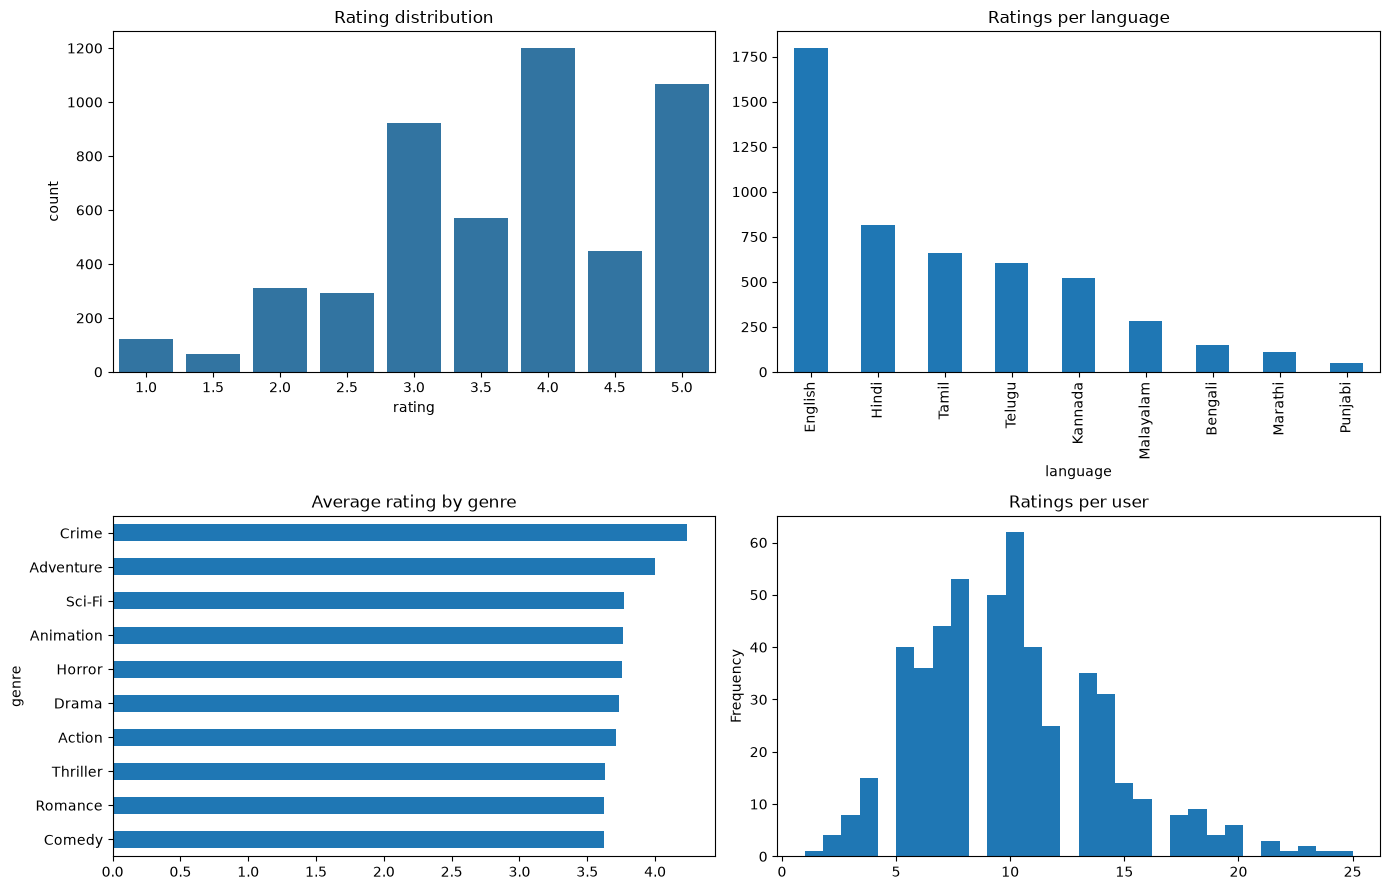

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(x='rating', data=df, ax=ax[0, 0]).set_title('Rating distribution')
df['language'].value_counts().plot.bar(ax=ax[0, 1], title='Ratings per language')
df.groupby('genre')['rating'].mean().sort_values().plot.barh(ax=ax[1, 0], title='Average rating by genre')
df['user_id'].value_counts().plot.hist(bins=30, ax=ax[1, 1], title='Ratings per user')
plt.tight_layout()
plt.savefig('../reports/eda_charts.png', dpi=120)

Ratings: most are 3.0–5.0, and 4.0 is the most common, so users tend to rate generously.
Languages: English has the most ratings (1,800), and Punjabi and Marathi have very few. This imbalance could cause a filter bubble.
Genres: average ratings are similar (3.6–4.2). Crime and Adventure look highest, but they have few ratings.
Ratings per user: most users have 5–15 ratings, and 95.5% of the user-movie grid is empty. That's the main challenge for collaborative filtering.

In [5]:
sparsity = 1 - len(df) / (df.user_id.nunique() * df.movie_title.nunique())
print(f"Users: {df.user_id.nunique()}, Movies: {df.movie_title.nunique()}, Sparsity: {sparsity:.2%}")

Users: 504, Movies: 222, Sparsity: 95.53%
